<a href="https://colab.research.google.com/github/nithinpalacherla-sys/Inventors/blob/main/CS2740_HW5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CS 2740 — Homework 5

**Name:**  
**GTID:**  
**Due:** Tuesday, October 20, 11:59pm (single PDF via Gradescope)

---

### Instructions

Run this notebook in **Google Colab**. Everything it uses is already installed there.

1. Fill in every cell marked `YOUR CODE HERE` and every written answer marked
   *Your answer here*. Double-click a text cell to edit it, and type math between
   dollar signs, for example `$\kappa = k_e/k_a$`.
2. Two parts ask for a drawing. Draw the compartment diagrams in Problems 2 and 3
   by hand, photograph them, and upload the photos when the cells ask for them.
   Colab deletes uploaded files when the runtime disconnects, so you may need to
   upload them again before your final run.
3. Cells marked *provided* run your code and draw the figures. You do not need to
   change them, but you do need to run them.
4. When you are done, run **Runtime → Restart and run all**.
5. Check your output before exporting. No cell output should be cut off, and every
   figure should fit on the page.
6. **File → Print → Save as PDF**, and submit that single PDF to Gradescope.

## Setup

In [1]:
import os

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageOps


def show_uploaded_image(filename, width=7):
    """
    Display a picture you have uploaded to Colab.

    If `filename` is not in the session files yet, an upload dialog opens, and
    whatever file you choose is saved under that name.
    """
    if not os.path.exists(filename):
        from google.colab import files
        print(f"{filename} not found. Choose your picture in the upload dialog.")
        uploaded = files.upload()
        os.rename(next(iter(uploaded)), filename)
    img = ImageOps.exif_transpose(Image.open(filename))
    img.thumbnail((1600, 1600))
    plt.figure(figsize=(width, width * img.height / img.width))
    plt.imshow(img)
    plt.axis("off")
    plt.show()


def ratio_table(labels, values, label_name="n"):
    """
    Provided. Print estimates together with the ratio of successive differences.
    A ratio near 2 means first order, near 4 second order, near 16 fourth order.
    """
    print(f"{label_name:>8} {'estimate':>18} {'difference':>14} {'ratio':>10}")
    diffs = [None] + [values[k] - values[k-1] for k in range(1, len(values))]
    for k, (lab, val) in enumerate(zip(labels, values)):
        d = diffs[k]
        if d is None:
            print(f"{lab:>8} {val:>18.12f}")
        elif k + 1 < len(values) and diffs[k+1] not in (None, 0.0):
            print(f"{lab:>8} {val:>18.12f} {d:>14.2e} {abs(d/diffs[k+1]):>10.2f}")
        else:
            print(f"{lab:>8} {val:>18.12f} {d:>14.2e}")

---

# Problem 1 — Numerical Integration

$$I = \int_0^1 e^x\,dx, \qquad I = e - 1$$

### (a) Both rules by hand at $n = 2$

Report each estimate to six decimal places and its error against the exact value.

With $n = 2$, $h = (1 - 0)/2 = 0.5$ and the nodes are $x_0 = 0$, $x_1 = 0.5$, $x_2 = 1$, so
$f(x_0) = e^0 = 1$, $f(x_1) = e^{0.5} \approx 1.648721$, $f(x_2) = e \approx 2.718282$.
The exact value is $I = e - 1 \approx 1.718282$.

**Trapezoid rule:**
$$T_2 = \frac{h}{2}\big[f(x_0) + 2f(x_1) + f(x_2)\big] = \frac{0.5}{2}\big[1 + 2(1.648721) + 2.718282\big] = 0.25(7.015724) \approx 1.753931$$
Error: $|T_2 - I| \approx |1.753931 - 1.718282| \approx 0.035649$.

**Simpson's rule:**
$$S_2 = \frac{h}{3}\big[f(x_0) + 4f(x_1) + f(x_2)\big] = \frac{0.5}{3}\big[1 + 4(1.648721) + 2.718282\big] = \frac{1}{6}(10.313167) \approx 1.718861$$
Error: $|S_2 - I| \approx |1.718861 - 1.718282| \approx 0.000579$.

### (b) The trapezoid rule

Write `trapezoid(f, a, b, n)`. With `x = np.linspace(a, b, n + 1)` you can evaluate `f` at every node at once, and `y[1:-1].sum()` adds the interior values.

In [3]:
def trapezoid(f, a, b, n):
    """
    TODO. Return the composite trapezoid estimate of the integral of f over
    [a, b] using n subintervals.
    """
    # YOUR CODE HERE
    x = np.linspace(a, b, n + 1)
    y = f(x)
    h = (b - a) / n
    return h / 2 * (y[0] + 2 * y[1:-1].sum() + y[-1])


# Provided. Compare with your hand answer from part (a).
print("trapezoid(exp, 0, 1, 2) =", trapezoid(np.exp, 0, 1, 2))
print("exact value             =", np.e - 1)

trapezoid(exp, 0, 1, 2) = 1.7539310924648253
exact value             = 1.718281828459045


### (c) Simpson's rule

Write `simpson(f, a, b, n)`. The weights run 1, 4, 2, 4, ..., 2, 4, 1, so `y[1:-1:2]` picks out the nodes weighted 4 and `y[2:-1:2]` those weighted 2. Raise an error when `n` is odd.

In [4]:
def simpson(f, a, b, n):
    """
    TODO. Return the composite Simpson estimate of the integral of f over
    [a, b] using n subintervals. Raise a ValueError when n is odd.
    """
    # YOUR CODE HERE
    if n % 2 != 0:
        raise ValueError("Simpson's rule needs an even number of subintervals.")
    x = np.linspace(a, b, n + 1)
    y = f(x)
    h = (b - a) / n
    return h / 3 * (y[0] + 4 * y[1:-1:2].sum() + 2 * y[2:-1:2].sum() + y[-1])


# Provided. Compare with your hand answer from part (a), then check the odd case.
print("simpson(exp, 0, 1, 2) =", simpson(np.exp, 0, 1, 2))
print("exact value           =", np.e - 1)
try:
    simpson(np.exp, 0, 1, 3)
    print("odd n was accepted, which it should not be")
except ValueError:
    print("odd n correctly refused")

simpson(exp, 0, 1, 2) = 1.7188611518765928
exact value           = 1.718281828459045
odd n correctly refused


### (d) Ratio columns

Run the provided cell, then report what each ratio column settles to and what order of accuracy each one indicates.

**Trapezoid:** the ratio column settles at $4.00$ for every row. Since $R \approx 2^p$, this gives $p = \log_2 4 = 2$, so the trapezoid rule is **second order**: doubling $n$ (halving $h$) makes the error about 4 times smaller.

**Simpson:** the ratio column settles at about $16$ (from $15.91$ up to $16.00$). This gives $p = \log_2 16 = 4$, so Simpson's rule is **fourth order**: doubling $n$ makes the error about 16 times smaller.

In [5]:
# Provided.
ns = [4 * 2**k for k in range(11)]

if trapezoid(np.exp, 0, 1, 2) is None or simpson(np.exp, 0, 1, 2) is None:
    print("Write trapezoid and simpson first, then run this cell.")
else:
    print("Trapezoid")
    ratio_table(ns, [trapezoid(np.exp, 0, 1, n) for n in ns])
    print("\nSimpson")
    ratio_table(ns, [simpson(np.exp, 0, 1, n) for n in ns])

Trapezoid
       n           estimate     difference      ratio
       4     1.727221904558
       8     1.720518592164      -6.70e-03       4.00
      16     1.718841128580      -1.68e-03       4.00
      32     1.718421660316      -4.19e-04       4.00
      64     1.718316786850      -1.05e-04       4.00
     128     1.718290568083      -2.62e-05       4.00
     256     1.718284013367      -6.55e-06       4.00
     512     1.718282374686      -1.64e-06       4.00
    1024     1.718281965016      -4.10e-07       4.00
    2048     1.718281862598      -1.02e-07       4.00
    4096     1.718281836994      -2.56e-08

Simpson
       n           estimate     difference      ratio
       4     1.718318841922
       8     1.718284154700      -3.47e-05      15.91
      16     1.718281974052      -2.18e-06      15.98
      32     1.718281837562      -1.36e-07      15.99
      64     1.718281829028      -8.53e-09      16.00
     128     1.718281828495      -5.33e-10      16.00
     256     1.718

### (e) Where Simpson stops improving

Run the provided cell, then report the smallest error Simpson reaches and explain what limits it.

The smallest error Simpson reaches is about $4.4 \times 10^{-16}$, at $n = 2048$, and it does not improve at $n = 4096$. The limit is **rounding error**: a double stores only about 16 significant digits, so once Simpson's own error falls below that level, adding more subintervals cannot make the answer more accurate.

In [6]:
# Provided.
exact = np.e - 1
if simpson(np.exp, 0, 1, 2) is None:
    print("Write simpson first, then run this cell.")
else:
    print(f"{'n':>8} {'Simpson error':>16}")
    for n in ns:
        print(f"{n:>8} {abs(simpson(np.exp, 0, 1, n) - exact):>16.3e}")
    print(f"\nmachine epsilon for doubles is {np.finfo(float).eps:.2e}")

       n    Simpson error
       4        3.701e-05
       8        2.326e-06
      16        1.456e-07
      32        9.103e-09
      64        5.690e-10
     128        3.556e-11
     256        2.223e-12
     512        1.392e-13
    1024        8.660e-15
    2048        4.441e-16
    4096        4.441e-16

machine epsilon for doubles is 2.22e-16


### (f) Area under a measured curve

The samples below are not equally spaced, which is normal when a quantity is measured densely while it changes fast and sparsely afterwards. Write `trapezoid_data(t, C)`, which applies the trapezoid rule panel by panel, then run the cell and answer below it.

Is your estimate high or low, and why does the shape of the curve make the sign of the error predictable?

The estimate is too high: about $32.77$ compared with the exact area of about $31.92$. This is predictable because $C(t) = 8e^{-t/4}$ is convex (concave up), since $C''(t) = \tfrac{1}{2}e^{-t/4} > 0$. For a convex curve, the straight top edge of each trapezoid lies above the curve, so every panel overcounts the area.

trapezoid estimate = 32.7705
exact area         = 31.9207


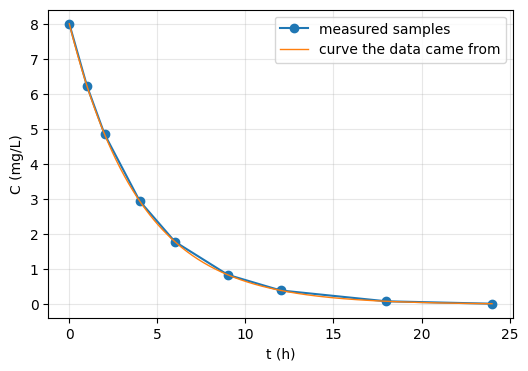

In [7]:
t_data = np.array([0, 1, 2, 4, 6, 9, 12, 18, 24], dtype=float)
C_data = np.array([8.000, 6.230, 4.852, 2.943, 1.785, 0.843, 0.398, 0.089, 0.020])


def trapezoid_data(t, C):
    """
    TODO. Return the area under the curve through the points (t, C), applying
    the trapezoid rule to each panel. The spacing is not uniform.
    """
    # YOUR CODE HERE
    widths = t[1:] - t[:-1]
    heights = (C[:-1] + C[1:]) / 2
    return float(np.sum(widths * heights))


# Provided. The data came from C(t) = 8 * exp(-t / 4).
area = trapezoid_data(t_data, C_data)
exact_area = 8 * 4 * (1 - np.exp(-24 / 4))
print("trapezoid estimate =", area)
print("exact area         =", round(exact_area, 4))

plt.figure(figsize=(6, 4))
plt.plot(t_data, C_data, "o-", label="measured samples")
tt = np.linspace(0, 24, 300)
plt.plot(tt, 8 * np.exp(-tt / 4), lw=1, label="curve the data came from")
plt.xlabel("t (h)")
plt.ylabel("C (mg/L)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

---

# Problem 2 — A Two-Compartment Drug Model

### (a) Compartment diagram

Draw the diagram by hand, labelling every box and every arrow with the flow it carries. Photograph it and run the cell below to upload and display it.

diagram_drug not found. Choose your picture in the upload dialog.


Saving Screenshot 2026-10-20 at 1.54.41 AM.png to Screenshot 2026-10-20 at 1.54.41 AM.png


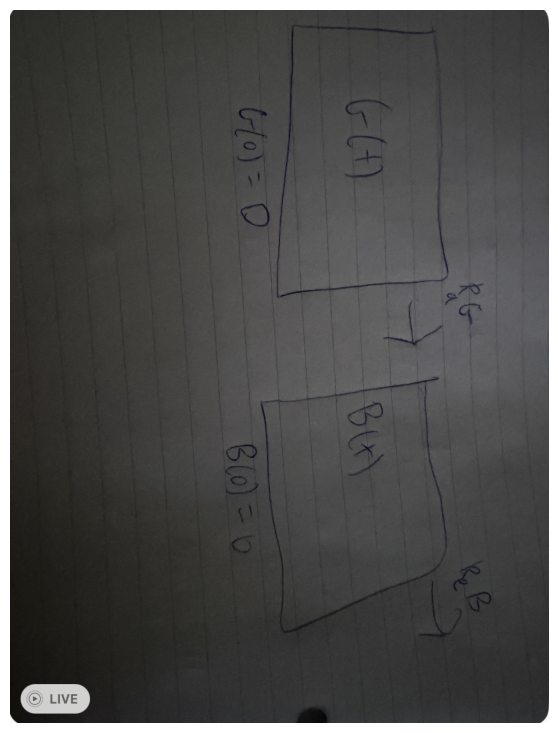

In [9]:
show_uploaded_image("diagram_drug")

### (b) The equations

Write the differential equations for $G(t)$ and $B(t)$, together with the initial conditions.

$$\frac{dG}{dt} = -k_a G, \frac{dB}{dt} = k_a G - k_e B,$$

with initial conditions

$$G(0) = D, B(0) = 0.$$

### (c) Units

State the units of $k_a$ and $k_e$, and say what $1/k_a$ means physically.

Both $k_a$ and $k_e$ have units of 1/time, since $\frac{dG}{dt}$ is in mg/h and $G$ is in mg. $1/k_a$ has units of time: it is the average time the drug stays in the gut before being absorbed into the blood.

### (d) Nondimensionalization

Show that setting $g = G/D$, $b = B/D$, $\tau = k_a t$ turns the system into

$$\frac{dg}{d\tau} = -g, \qquad \frac{db}{d\tau} = g - \kappa b,$$

identify $\kappa$, and explain what the reduction from three parameters to one says about two patients given different doses of the same drug.

By the chain rule, $\frac{d}{dt} = k_a \frac{d}{d\tau}$. Substituting $G = Dg$, $B = Db$ and dividing by $k_a D$ gives $\frac{dg}{d\tau} = -g$ and $\frac{db}{d\tau} = g - \frac{k_e}{k_a} b$, so $\kappa = \frac{k_e}{k_a}$.

The dose $D$ drops out, so two patients taking different doses of the same drug follow the same curve, just scaled by their dose.

### (e) What $\kappa$ compares

Which two processes does $\kappa$ compare? Describe in words what the drug does differently when $\kappa \ll 1$ and when $\kappa \gg 1$.

$\kappa = k_e/k_a$ compares the rate of elimination from the blood with the rate of absorption from the gut.

$\kappa \ll 1$:** absorption is much faster than elimination, so the drug quickly builds up to a high peak in the blood and then slowly wears off.

$\kappa \gg 1$:** elimination is much faster than absorption, so the drug is removed almost as soon as it arrives, and the blood level stays low.

---

# Problem 3 — Reading a Model

$$\dot S = -\frac{\beta S I}{N}, \qquad \dot E = \frac{\beta S I}{N} - \sigma E, \qquad \dot I = \sigma E - \gamma I, \qquad \dot R = \gamma I$$

with $N = S + E + I + R$.

### (a) Compartment diagram

Draw the diagram this system describes, photograph it, and run the cell below.

diagram_seir not found. Choose your picture in the upload dialog.


Saving Screenshot 2026-10-20 at 1.54.57 AM.png to Screenshot 2026-10-20 at 1.54.57 AM.png


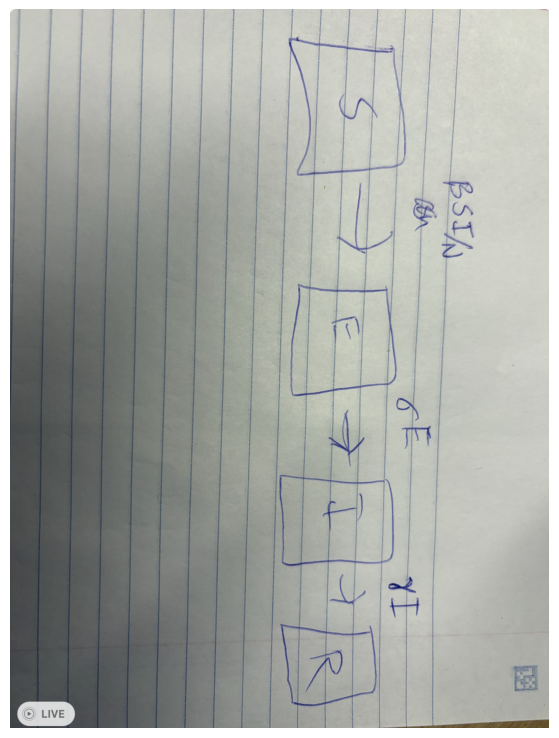

In [10]:
show_uploaded_image("diagram_seir")

### (b) Rate laws and conservation

For each of the three flows, name the rate law it uses and the modeling assumption that choice encodes. Then show from the equations that $N$ is constant, and say what $1/\sigma$ and $1/\gamma$ mean physically.

1. $S \to E$, rate $\beta SI/N$: mass action. The rate is proportional to $S \cdot I$, which assumes the population is well mixed, so infections happen through random contacts between susceptible and infected people.
2. $E \to I$, rate $\sigma E$: linear (first-order). Each exposed person becomes infectious at the same constant rate, independently of others, so the latent period is exponentially distributed.
3. $I \to R$, rate $\gamma I$: linear (first-order). Each infected person recovers at the same constant rate, independently, so the infectious period is exponentially distributed. Recovered people stay immune, since nothing flows out of $R$.

**$N$ is constant:**
$$\dot N = \dot S + \dot E + \dot I + \dot R = -\frac{\beta SI}{N} + \left(\frac{\beta SI}{N} - \sigma E\right) + (\sigma E - \gamma I) + \gamma I = 0.$$
Each flow leaves one compartment and enters another, so the terms cancel.

Physical meanings: $1/\sigma$ is the average latent period (the time from infection to becoming contagious), and $1/\gamma$ is the average infectious period (the time spent contagious before recovering).